# Proyecto 2 — EEG con parpadeos reales (Eye-BCI): sacar el EOG con RLS

**Cómo leer este notebook:** igual que `proyecto1_eyebci.ipynb`. Cada sección empieza con un recuadro **"Dónde estamos"**. Antes de cada celda de código hay un bloque que dice qué hace y por qué. Debajo de cada gráfico o tabla hay un **"Qué mirar"** con lo que se ve y los números medidos.

---

## Qué pide el proyecto 2
Resolver el problema del proyecto 1 con **RLS** (o algoritmos basados en RLS), justificar cada decisión y **comparar RLS con LMS en condiciones parecidas**.

## De dónde partimos (proyecto 1)
Mismo dataset (Eye-BCI, sujeto 1, sesión 1), mismas señales y mismo esquema de cancelación:

- **`y(n)`:** un electrodo (`Fp1`, `Fp2`; `Pz` de control).
- **`x(n) = [HEO(n), HEO(n−1), HEO(n−2)]`:** la referencia, el único canal de EOG. FIR de `M = 3`.
- **`e(n) = y(n) − wᵀx(n)`:** el EEG estimado.

Lo que aprendimos y que condiciona este notebook:

| Resultado del proyecto 1 | Por qué importa para RLS |
|---|---|
| NLMS con δ chico no anda: `w(n)` salta de −6 a +5. | `HEO` tiene **52 veces menos potencia entre parpadeos**. NLMS normaliza por `‖x(n)‖²` y da pasos enormes justo cuando no hay nada que aprender. **RLS también normaliza** (por `R̂(n)`), así que puede caer en lo mismo. |
| Lo arregló `δ = 100·M·P_x`, `μ̃ = 0.3`: RRMSE 0.22 en el semi-sintético, ≈ Wiener en datos reales. | Es la vara contra la que se compara RLS. |
| Los coeficientes no llegan uno por uno a `w_o`, solo su suma (spread de `R` = 2685). | LMS/NLMS se frenan con el spread; **RLS no debería**. Hay que verificarlo. |

## Notación: `λ` cambia de significado
En el proyecto 1, `λ` era la fracción de parpadeo que llega a cada electrodo. En RLS, `λ` es el **factor de olvido** (como en las diapositivas de la materia). Para no mezclarlos, **acá la fracción de parpadeo se llama `β`**:

`y(n) = s(n) + β·η_EOG(n)`

## Índice
1. **Carga** (igual que el proyecto 1).
2. **Inspección**: un repaso corto y una pregunta nueva: ¿cada cuánto hay un parpadeo? Eso da la primera cota para `λ`.
3. **El filtro: RLS**: implementación y chequeos.
4. **Primera corrida y diagnóstico** sobre los datos reales.
5. **Semi-sintético**: elegir `λ` y `δ` con una respuesta conocida, y comparar con LMS.
6. **Datos reales**: RLS elegido contra NLMS, LMS y Wiener.
7. **Conclusiones**.

## §1. Carga

> **Dónde estamos:** la carga es la misma del proyecto 1 (§1 de `proyecto1_eyebci.ipynb`, ahí está explicado cada paso). Se repite acá para que el notebook corra solo.
>
> Pasos: parámetros → carga y alineación → chequeo de lo que se cargó.

### 1.1 Parámetros
Los mismos que en el proyecto 1:
- **`FS = 250`:** submuestreo de 1000 a 250 Hz. EEG y EOG están por debajo de ~40 Hz.
- **`T_INI, T_FIN = 2, 338`:** después de la tarea la señal se rompe; los primeros 2 s son el transitorio del pasa-altos.
- **`F_HP = 0.5`:** el mismo pasa-altos en todos los canales, a `y` y a `x` por igual.
- **`CANALES_MALOS`:** los 11 canales que el artículo declara defectuosos.

In [1]:
import json
import numpy as np
import pandas as pd
import mne
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, lfilter, welch

mne.set_log_level("ERROR")

# Parámetros (los del proyecto 1)
RAIZ = "./datasets-presentacion-PASA/Sess01"
ARCHIVO = "ME011"           # Sujeto 01, sesión 1
FS_ORIG = 1000              # fs del .bdf [Hz]
FS = 250                    # Submuestreo 1000 -> 250 Hz
T_INI, T_FIN = 2, 338       # Ventana útil [s]
F_HP = 0.5                  # Pasa-altos [Hz], igual en todos los canales
CANAL_EOG = "HEO"
CANALES_MALOS = ["PO3", "F1", "POz", "Oz", "F3", "O2", "P8", "PO7", "FC3", "P7", "P4"]  # Defectuosos según el artículo

### 1.2 Carga y alineación
`cargar()` es la del proyecto 1: pasa-altos → submuestreo → recorte → µV → sin continua. Después lee de `_sync.csv` dónde está cada parpadeo (columna `Blinks`) y en qué fase de la tarea está cada muestra (columna `Cues`).

In [2]:
def cargar():
    """
    Carga el .bdf. Devuelve:
        datos: dict {canal: señal en µV}, con pasa-altos F_HP, submuestreada a FS y recortada a [T_INI, T_FIN]
        t_disparos: instantes [s] en que el canal Trig marca el comienzo de una repetición
    """
    raw = mne.io.read_raw_bdf(f"{RAIZ}/{ARCHIVO}.bdf", preload=True, stim_channel=None)
    trig = raw.get_data(picks=["Trig"])[0]
    t_disparos = np.flatnonzero(np.diff(trig) > 0) / FS_ORIG   # Flancos de subida del disparo
    raw.drop_channels(["Trig"])               # El disparo no es una señal
    raw.filter(F_HP, None)                    # Mismo pasa-altos para y y para x
    raw.resample(FS)                          # MNE aplica el antialias
    raw.crop(T_INI, T_FIN)
    X = raw.get_data() * 1e6                  # V -> µV
    X = X - X.mean(axis=1, keepdims=True)     # Sin continua
    return dict(zip(raw.ch_names, X)), t_disparos


DATOS, t_disparos = cargar()
N_MUESTRAS = len(DATOS[CANAL_EOG])
t = T_INI + np.arange(N_MUESTRAS) / FS        # Tiempo de cada muestra [s], en el reloj del .bdf

# _sync.csv: una fila por ms. Time está en el reloj del .bdf
sync = pd.read_csv(f"{RAIZ}/{ARCHIVO}_sync.csv", usecols=["Time", "Cues", "Blinks"], dtype={"Cues": str})
t_parpadeos = sync["Time"].values[sync["Blinks"].values == 1]                     # Picos de parpadeo [s]
t_parpadeos = t_parpadeos[(t_parpadeos > T_INI) & (t_parpadeos < T_FIN)]           # Solo los del recorte
PARPADEOS = np.round((t_parpadeos - T_INI) * FS).astype(int)                       # Índices a FS

# Fase de la tarea en cada muestra
NOMBRE_FASE = {"Welcome": "otra", "Goodbye": "otra", "Fixation": "fijación",
               "Left": "ejecución", "Right": "ejecución", "Random": "descanso"}
cues = sync["Cues"].ffill().fillna("Welcome").values
FASE = np.array([NOMBRE_FASE[c] for c in cues[np.searchsorted(sync["Time"].values, t)]])

CANALES_EEG = [n for n in DATOS if n not in ["M1", "M2", CANAL_EOG]]
CANALES_BUENOS = [n for n in CANALES_EEG if n not in CANALES_MALOS]

print(f"{len(DATOS)} canales ({len(CANALES_BUENOS)} de EEG buenos)")
print(f"{N_MUESTRAS / FS:.0f} s a {FS} Hz (recorte {T_INI}-{T_FIN} s)")
print(f"{len(t_disparos)} repeticiones; {len(PARPADEOS)} parpadeos marcados en el recorte "
      f"({len(PARPADEOS) / (N_MUESTRAS / FS) * 60:.1f} por minuto)")

65 canales (51 de EEG buenos)
336 s a 250 Hz (recorte 2-338 s)
40 repeticiones; 75 parpadeos marcados en el recorte (13.4 por minuto)


### Qué mirar: lo que se cargó
- **65 canales, 51 de EEG buenos**, 336 s a 250 Hz: lo mismo que en el proyecto 1.
- **75 parpadeos en el recorte (13.4 por minuto)** y 40 repeticiones de la tarea.

## §2. Inspección

> **Dónde estamos:** las señales son las del proyecto 1, así que la inspección completa ya está hecha (§2 de `proyecto1_eyebci.ipynb`). Acá se repite lo mínimo para tener los números a mano, y se agrega lo que RLS necesita y NLMS no.
>
> Preguntas, en orden:
> 1. ¿Cómo se ven los parpadeos? (repaso)
> 2. ¿Cuánto parpadeo llega a cada canal? (repaso: `β` y la elección de `y`)
> 3. Resumen del resto de la inspección del proyecto 1.
> 4. **Nueva:** ¿cada cuánto hay un parpadeo? Comparado con la memoria de RLS para cada `λ`.
> 5. **Nueva:** ¿qué potencia de `HEO` "ve" RLS en cada instante, según `λ`?

### 2.1 Los parpadeos a simple vista (repaso)
60 s (de 30 a 90 s) de `HEO`, `Fp1`, `Fp2` y `Pz`. Rojo: parpadeos marcados por `Blinks`. Naranja: ejecución del movimiento.

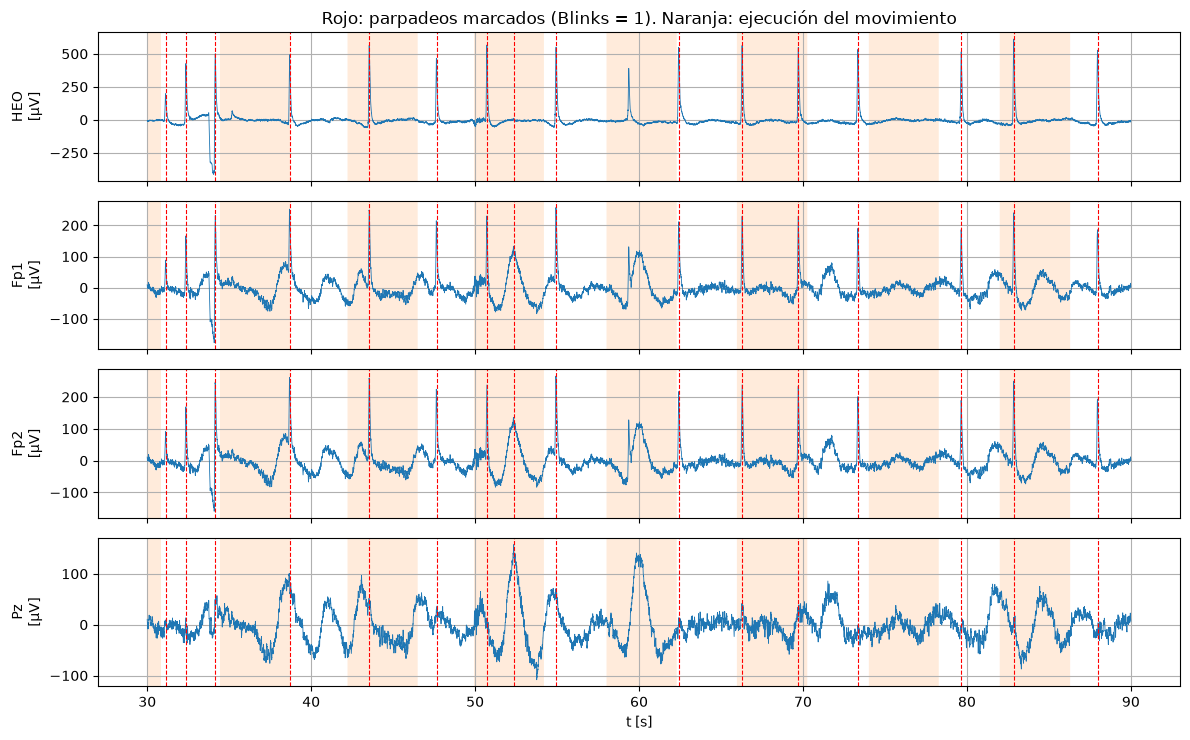

In [3]:
CANALES_VER = [CANAL_EOG, "Fp1", "Fp2", "Pz"]
T_VER = (30, 90)                                   # Tramo a mirar [s]

i0, i1 = [int((tv - T_INI) * FS) for tv in T_VER]
fig, axs = plt.subplots(len(CANALES_VER), 1, figsize=(12, 7.5), sharex=True)
for ax, n in zip(axs, CANALES_VER):
    ax.plot(t[i0:i1], DATOS[n][i0:i1], lw=0.6)
    ax.fill_between(t[i0:i1], 0, 1, where=FASE[i0:i1] == "ejecución", transform=ax.get_xaxis_transform(),
                    color="tab:orange", alpha=0.15, lw=0)
    for k in PARPADEOS[(PARPADEOS >= i0) & (PARPADEOS < i1)]:
        ax.axvline(t[k], color="r", lw=0.8, ls="--")
    ax.set_ylabel(f"{n}\n[µV]")
    ax.grid(True)
axs[0].set_title("Rojo: parpadeos marcados (Blinks = 1). Naranja: ejecución del movimiento")
axs[-1].set_xlabel("t [s]")
plt.tight_layout()
plt.show()

### Qué mirar: los parpadeos en el tiempo
- **Cada línea roja cae sobre un pico:** ~250–550 µV en `HEO`, ~200 µV en `Fp1` y `Fp2`, casi nada en `Pz`.
- **Lo que importa para este notebook es el espacio entre picos:** `HEO` queda casi plano (±20 µV) durante varios segundos y después tiene un pico de ~0.2 s. Toda la información sobre cuánto parpadeo llega a `Fp1` está en esos picos.
- **No todo pico de `HEO` está marcado:** el de ~380 µV a los 59.4 s no tiene línea roja, y la deflexión de −400 µV a los 34 s es un movimiento de ojos, no un parpadeo. El filtro los ve igual, porque están en `x`; las marcas solo se usan para medir.
- Las ondas lentas de `Pz` (y de todos los canales de EEG) son la parte común que no está en `HEO` (2.3).

### 2.2 Cuánto parpadeo llega a cada canal (repaso)
Promedio sincronizado: recortar ±1 s alrededor de cada parpadeo y promediar. Lo atado al parpadeo se suma; el EEG tiende a 0. El cociente entre el pico de cada canal y el de `HEO` estima **`β`**, la fracción del parpadeo de la referencia que llega a ese electrodo (en el proyecto 1 lo llamábamos `λ`).

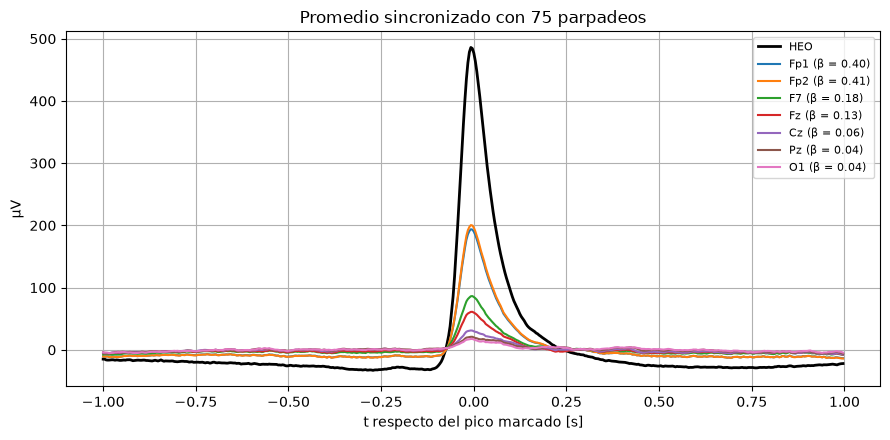

β más grandes: {'Fp2': 0.41, 'Fpz': 0.41, 'Fp1': 0.4, 'AF3': 0.32, 'AF4': 0.23}
β atrás: {'Cz': 0.06, 'Pz': 0.04, 'O1': 0.04}


In [4]:
VENTANA = int(1 * FS)                              # ±1 s alrededor de cada parpadeo
tau = np.arange(-VENTANA, VENTANA) / FS


def promedio_sincronizado(x, picos):
    """Promedio de x en ventanas de ±VENTANA alrededor de cada pico."""
    tramos = [x[k - VENTANA:k + VENTANA] for k in picos if VENTANA <= k < len(x) - VENTANA]
    return np.mean(tramos, axis=0)


prom_eog = promedio_sincronizado(DATOS[CANAL_EOG], PARPADEOS)
k_pico = np.argmax(np.abs(prom_eog))               # Muestra del pico del parpadeo promedio en HEO
BETA = pd.Series({n: promedio_sincronizado(DATOS[n], PARPADEOS)[k_pico] / prom_eog[k_pico]
                  for n in CANALES_BUENOS})        # β: amplitud en el canal / amplitud en HEO

CANALES_PROM = ["Fp1", "Fp2", "F7", "Fz", "Cz", "Pz", "O1"]   # De adelante hacia atrás
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(tau, prom_eog, "k", lw=2, label=CANAL_EOG)
for n in CANALES_PROM:
    ax.plot(tau, promedio_sincronizado(DATOS[n], PARPADEOS), label=f"{n} (β = {BETA[n]:.2f})")
ax.set_title(f"Promedio sincronizado con {len(PARPADEOS)} parpadeos")
ax.set_xlabel("t respecto del pico marcado [s]")
ax.set_ylabel("µV")
ax.grid(True)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print("β más grandes:", BETA.sort_values(ascending=False).head(5).round(2).to_dict())
print("β atrás:", BETA[["Cz", "Pz", "O1"]].round(2).to_dict())

### Qué mirar: el parpadeo promedio
- **Igual que en el proyecto 1:** pico de 485 µV en `HEO`, ~200 µV en `Fp1`/`Fp2` (`β` ≈ 0.4) y 15–30 µV atrás (`β` ≈ 0.04 en `Pz` y `O1`).
- **Misma forma y mismo instante en todos los canales:** solo cambia la escala. El camino ojo→electrodo es casi una ganancia.
- **Para el filtro:** en `Fp1` hay que aprender, en esencia, un número (`β ≈ 0.4`), y solo se puede aprender cuando hay parpadeo.

### 2.3 El resto de la inspección del proyecto 1, en una tabla
No se repite: está en §2.5–§2.10 de `proyecto1_eyebci.ipynb`. Lo que sale de ahí y se mantiene acá:

| Pregunta | Respuesta (proyecto 1) | Qué decide |
|---|---|---|
| ¿Retardo ojo→electrodo? | 0 ms (≤ 1 muestra): el camino es casi una ganancia. | `M = 3` alcanza (se verificó con un barrido de 1 a 8). |
| ¿`HEO` trae EEG? | ρ(`HEO`, `Fp1`) = 0.9 con parpadeos y ≈ 0.17 sin ellos; mediana de los canales ≈ 0. | `HEO` sirve de referencia: casi no hay EEG que se pueda restar por error. |
| ¿Frecuencias? | El EOG está por debajo de ~10 Hz, encima de δ y θ. | Un pasa-altos fijo se llevaría EEG: hace falta el filtro adaptativo. |
| ¿Ruido que no es de los ojos? | Una parte lenta (0.5–3 Hz) común a todos los canales de EEG, que no está en `HEO`. | Ningún filtro con esta referencia la saca: queda en `e(n)`. |
| ¿Señal sin parpadeos? | 78 % del tiempo, en tramos cortos (mediana 3.2 s). | Es lo que vuelve frágil a un algoritmo que normaliza (proyecto 1, §4). |

**Decisiones:** `y` = `Fp1` y `Fp2`, `Pz` de control, `x` = `HEO`, `M = 3`.

### 2.4 ¿Cada cuánto hay un parpadeo? (nueva: primera cota para `λ`)
**Por qué importa.** RLS minimiza `E(n) = Σ λ^(n−j) |e(j)|²`: los datos de hace `k` muestras pesan `λ^k`. La **memoria** del algoritmo es

`τ = −1 / ln λ ≈ 1 / (1 − λ)` muestras.

En este problema, **la información para aprender `w` está solo en los parpadeos**: entre parpadeos `HEO` casi no se mueve y `e(n)` es EEG, que no tiene nada que ver con `x(n)` (proyecto 1, §4). Si la memoria de RLS es más corta que el tiempo entre parpadeos, entre uno y otro el algoritmo **se olvida del último parpadeo** y se queda aprendiendo solo de EEG.

La celda calcula el tiempo entre parpadeos consecutivos y lo compara con `τ` para varios `λ`.

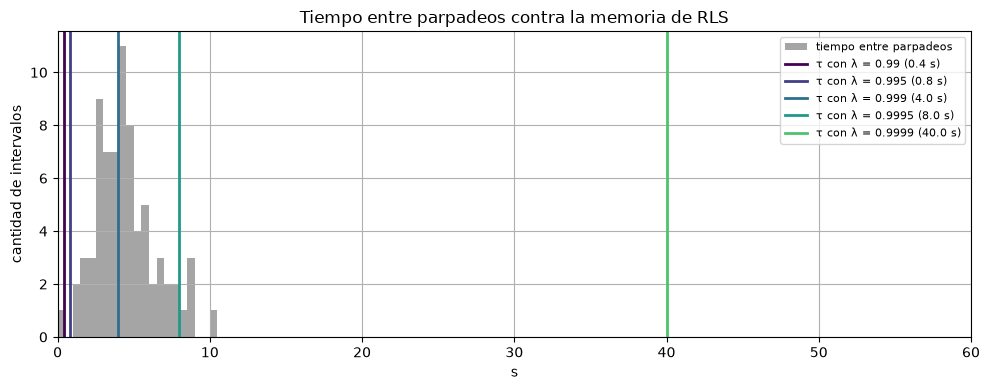

         τ [muestras]  τ [s]  parpadeos en τ  % intervalos > τ
λ                                                             
0.99000          99.0    0.4             0.1              99.0
0.99500         199.0    0.8             0.2              99.0
0.99900         999.0    4.0             0.9              57.0
0.99950        1999.0    8.0             1.8               7.0
0.99990        9999.0   40.0             9.0               0.0
0.99995       19999.0   80.0            17.9               0.0

Tiempo entre parpadeos: media 4.5 s, mediana 4.2 s, mínimo 0.2 s, máximo 10.2 s


In [5]:
intervalos = np.diff(PARPADEOS) / FS              # Tiempo entre parpadeos consecutivos [s]
LAMBDAS = [0.99, 0.995, 0.999, 0.9995, 0.9999, 0.99995]


def memoria(lam):
    """τ = -1/ln λ, en segundos."""
    return -1 / np.log(lam) / FS


fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(intervalos, bins=np.arange(0, intervalos.max() + 1, 0.5), color="tab:gray", alpha=0.7,
        label="tiempo entre parpadeos")
colores = plt.cm.viridis(np.linspace(0, 0.9, len(LAMBDAS)))
for lam, c in zip(LAMBDAS, colores):
    if memoria(lam) < 60:
        ax.axvline(memoria(lam), color=c, lw=2, label=f"τ con λ = {lam} ({memoria(lam):.1f} s)")
ax.set_xlabel("s")
ax.set_ylabel("cantidad de intervalos")
ax.set_title("Tiempo entre parpadeos contra la memoria de RLS")
ax.set_xlim(0, 60)
ax.grid(True)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

filas = {lam: {"τ [muestras]": round(-1 / np.log(lam)), "τ [s]": round(memoria(lam), 1),
               "parpadeos en τ": round(memoria(lam) / intervalos.mean(), 1),
               "% intervalos > τ": round(100 * np.mean(intervalos > memoria(lam)))} for lam in LAMBDAS}
print(pd.DataFrame(filas).T.rename_axis("λ").to_string())
print(f"\nTiempo entre parpadeos: media {intervalos.mean():.1f} s, mediana {np.median(intervalos):.1f} s, "
      f"mínimo {intervalos.min():.1f} s, máximo {intervalos.max():.1f} s")

### Qué mirar: tiempo entre parpadeos y memoria
- **Hay un parpadeo cada 4.5 s en promedio** (mediana 4.2 s). El intervalo más largo es de 10.2 s. El mínimo, 0.2 s, es un parpadeo doble.
- **Con `λ = 0.99` (el valor "de libro") la memoria es 0.4 s:** el 99 % de los intervalos son más largos. Entre un parpadeo y el siguiente, RLS se olvida del parpadeo casi por completo y aprende solo de EEG.
- **Con `λ = 0.999` (4 s), el 57 % de los intervalos son más largos que la memoria.** Todavía se olvida en la mitad de los casos.
- **Con `λ = 0.9995` (8 s) ya solo el 7 %, y con `λ ≥ 0.9999` (40 s o más) ninguno:** la memoria abarca 9 parpadeos o más.
- **Primera cota:** para que en la memoria de RLS siempre haya algún parpadeo, **`λ ≳ 0.9995`**. Para que haya varios, `λ ≈ 0.9999`.
- **Lo que esta cuenta no dice:** si `λ` cerca de 1 tiene alguna desventaja. La teoría (`9. RLS.pdf`) dice que el desajuste es `≈ M·(1−λ)/(1+λ)`, que también baja con `λ → 1`. El costo es el tracking: no podría seguir un camino ojo→electrodo que cambie más rápido que `τ`. Si el camino es una ganancia fija, como parece, eso no molesta. Lo medimos en §5.

### 2.5 ¿Qué potencia de `HEO` "ve" RLS en cada instante? (nueva)
**La cuenta.** RLS estima la correlación de la entrada con la misma ventana exponencial:

`R̂(n) = λ·R̂(n−1) + x(n)xᵀ(n)`

y la ganancia que corrige `w` es `g(n) = R̂⁻¹(n)·x(n)`. Para `M = 1` es una cuenta escalar: `R̂(n) ≈ P_λ(n) / (1 − λ)`, con

`P_λ(n) = (1 − λ)·Σ λ^(n−j) x²(j)`

la **potencia de `HEO` promediada con la ventana de RLS**. La corrección queda `Δw = x(n)·e(n)·(1 − λ) / P_λ(n)`: cuando `P_λ` baja, el paso sube, igual que `μ(n) = μ̃ / ‖x(n)‖²` en NLMS. **NLMS con δ chico es el caso extremo: estima la potencia con solo las `M = 3` últimas muestras.** RLS la estima con `τ` muestras.

La celda calcula `P_λ(n)` para tres `λ` (un filtro IIR de primer orden sobre `x²`) y la compara con `‖x(n)‖² / M`, lo que usaba NLMS.

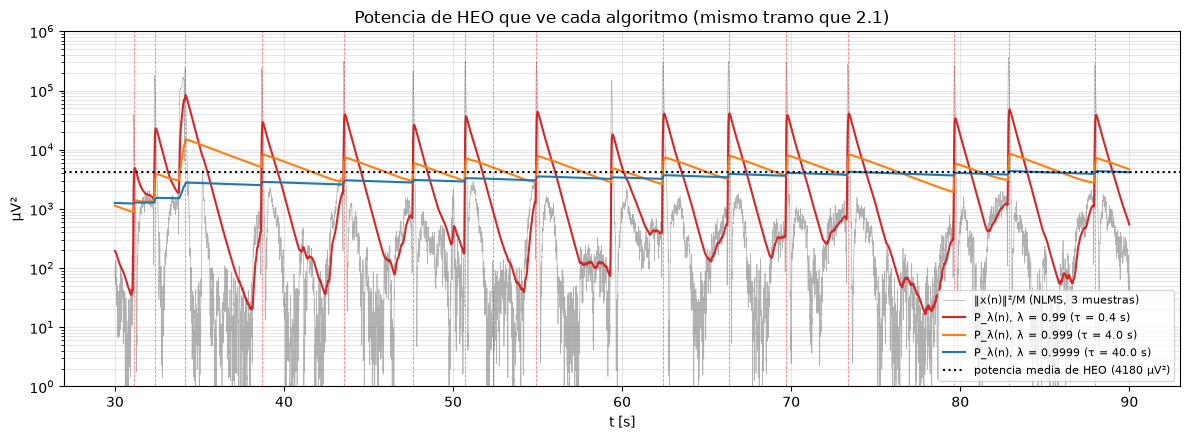

                   τ [s] P_λ mín [µV²] P_λ máx [µV²] máx / mín media / mín
0.99                 0.4          15.0       83319.0    5462.1       275.0
0.995                0.8          35.0       52346.0    1485.7       119.4
0.999                4.0         616.0       14867.0      24.1         6.9
0.9995               8.0        1446.0        8794.0       6.1         2.9
0.9999              40.0        3110.0        5451.0       1.8         1.3
0.99995             80.0        3312.0        4687.0       1.4         1.2
NLMS (3 muestras)  0.012           0.0        426024     2e+07       2e+05


In [6]:
x2 = DATOS[CANAL_EOG]**2


def potencia_lambda(lam, x2=x2):
    """P_λ(n) = (1-λ) Σ λ^(n-j) x²(j): un IIR de primer orden sobre x²."""
    return lfilter([1 - lam], [1, -lam], x2)


pot_nlms = np.convolve(x2, np.ones(3), mode="full")[:N_MUESTRAS] / 3    # ‖x(n)‖² / M con M = 3
LAMBDAS_VER = [0.99, 0.999, 0.9999]

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.semilogy(t[i0:i1], pot_nlms[i0:i1], color="tab:gray", lw=0.5, alpha=0.6, label="‖x(n)‖²/M (NLMS, 3 muestras)")
for lam, c in zip(LAMBDAS_VER, ["tab:red", "tab:orange", "tab:blue"]):
    ax.semilogy(t[i0:i1], potencia_lambda(lam)[i0:i1], color=c, lw=1.5,
                label=f"P_λ(n), λ = {lam} (τ = {memoria(lam):.1f} s)")
for k in PARPADEOS[(PARPADEOS >= i0) & (PARPADEOS < i1)]:
    ax.axvline(t[k], color="r", lw=0.6, ls="--", alpha=0.5)
ax.axhline(x2.mean(), color="k", ls=":", label=f"potencia media de HEO ({x2.mean():.0f} µV²)")
ax.set_ylim(1, 1e6)
ax.set_xlabel("t [s]")
ax.set_ylabel("µV²")
ax.set_title("Potencia de HEO que ve cada algoritmo (mismo tramo que 2.1)")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

# Cuánto varía P_λ(n) en toda la grabación (sin el transitorio inicial de 3τ)
filas = {}
for lam in LAMBDAS:
    p = potencia_lambda(lam)[int(3 * memoria(lam) * FS):]
    filas[lam] = {"τ [s]": round(memoria(lam), 1), "P_λ mín [µV²]": round(p.min()),
                  "P_λ máx [µV²]": round(p.max()), "máx / mín": round(p.max() / p.min(), 1),
                  "media / mín": round(p.mean() / p.min(), 1)}
p = pot_nlms[FS:]
filas["NLMS (3 muestras)"] = {"τ [s]": round(3 / FS, 3), "P_λ mín [µV²]": round(p.min(), 1),
                              "P_λ máx [µV²]": round(p.max()), "máx / mín": f"{p.max() / p.min():.0e}",
                              "media / mín": f"{p.mean() / p.min():.0e}"}
print(pd.DataFrame(filas).T.to_string())

### Qué mirar: la potencia que ve RLS
- **Gris (NLMS, 3 muestras):** varía entre ~1 y ~4·10⁵ µV². Es lo que hacía que NLMS con δ chico diera pasos enormes entre parpadeos (proyecto 1, §4). En toda la grabación, máx/mín ≈ 2·10⁷.
- **Rojo (`λ = 0.99`):** el mismo problema, un poco más suave. Sube en cada parpadeo y en ~1 s ya bajó 100 veces. **Entre parpadeos, la potencia que ve RLS cae a 15–100 µV², ~275 veces menos que la media.** Ahí la ganancia `g(n)` es enorme, y en ese momento `e(n)` es solo EEG. **Predicción: con `λ = 0.99`, RLS va a fallar como NLMS con δ chico.** Lo probamos en §4.
- **Naranja (`λ = 0.999`):** diente de sierra entre ~3·10³ y ~1.5·10⁴ µV². Varía 24 veces en toda la grabación.
- **Azul (`λ = 0.9999`):** casi plana, cerca de la potencia media de `HEO` (4180 µV²). Máx/mín = 1.8: **el paso de RLS es prácticamente constante, como LMS o como NLMS con δ grande**, que fue lo que anduvo en el proyecto 1.
- **El arranque:** la azul tarda en subir (todavía está en ~1300 µV² a los 30 s, 28 s después del comienzo) porque la ventana se está llenando. Durante los primeros ~`τ` segundos, `R̂(n)` es chica y la ganancia es grande. **Ahí es donde importa la inicialización `P(−1) = δ⁻¹·I`:** δ hace de energía "inventada" mientras la ventana se llena. Con `λ` cerca de 1 ese arranque dura mucho, así que δ no es un detalle. Lo elegimos en §5.
- **La analogía con el proyecto 1:** `λ` cumple el papel que tenía δ en NLMS. Las dos cosas deciden cuánto se promedia la energía de la referencia antes de normalizar.

### Conclusiones de §2
| Pregunta | Respuesta | Qué decide |
|---|---|---|
| ¿Qué cambia respecto del proyecto 1? | Nada en los datos: mismos parpadeos, `β` ≈ 0.4 en `Fp1`/`Fp2`, 0.04 en `Pz`. | Mismas `y` (`Fp1`, `Fp2`, `Pz` de control), misma `x` (`HEO`), `M = 3`. |
| ¿Cada cuánto hay un parpadeo? | Cada 4.5 s en promedio, nunca más de 10.2 s. | La memoria de RLS tiene que ser de varios segundos. |
| ¿Qué memoria hace falta? | Con `λ = 0.99` (0.4 s), RLS ve 275 veces menos potencia entre parpadeos que en promedio. Con `λ = 0.9999` (40 s), la potencia que ve es casi constante (máx/mín = 1.8). | **Hipótesis: `λ ≈ 0.9995–0.9999`.** `λ = 0.99` debería fallar como NLMS con δ chico. |
| ¿Qué más hay que elegir? | Con `λ` cerca de 1, la ventana tarda ~`τ` en llenarse. | δ de la inicialización `P(−1) = δ⁻¹·I` importa, y se elige junto con `λ`. |

**Lo que sigue (§3–§4):** implementar RLS, chequearlo con una respuesta conocida y correrlo sobre `Fp1` con `λ = 0.99` para ver si falla como predecimos.

## §3. El filtro: RLS con HEO como referencia

> **Dónde estamos:** sabemos qué hay en las señales y tenemos una hipótesis para `λ` (§2). Ahora corremos el filtro, con los mismos pasos que §3 del proyecto 1:
> 1. Las funciones: las del proyecto 1, más `rls()`.
> 2. Sanity check: que el código haga lo que dice la teoría, con una respuesta conocida.
> 3. Primera corrida sobre los datos reales: `y` = `Fp1`, `Fp2` y `Pz` (control), `x` = `HEO`.
> 4. Pruebas sobre esa corrida: en el tiempo, los coeficientes, si el parpadeo desaparece y si se daña el EEG fuera de los parpadeos.
>
> **No hay ground truth:** de 3.3 en adelante todo son pruebas indirectas, como en el proyecto 1.

### 3.1 Funciones
Copiadas tal cual de `proyecto1_eyebci.ipynb`, §3–§4: `armar_regresor`, `matriz_regresores`, `wiener` (la solución `w_o = R⁻¹p` con promedios temporales, más `J_min`, autovalores y spread), `rrmse`, `nlms` y `lms`. NLMS y LMS se usan para comparar.

**Nueva: `rls(y, refs, M, lam, delta)`**, el RLS convencional del resumen de `9. RLS.pdf`. Para cada `n`:

| Paso | Cuenta |
|---|---|
| Ganancia alternativa | `ḡ(n) = λ⁻¹·P(n−1)·x(n)` |
| Factor de conversión | `ᾱ(n) = 1 + ḡᵀ(n)·x(n)` |
| Ganancia | `g(n) = ḡ(n) / ᾱ(n)` |
| Inversa de la correlación | `P(n) = λ⁻¹·P(n−1) − g(n)·ḡᵀ(n)` |
| Error a priori | `e(n) = y(n) − wᵀ(n−1)·x(n)` |
| Coeficientes | `w(n) = w(n−1) + g(n)·e(n)` |

con `P(−1) = δ⁻¹·I` y `w(−1) = 0`. Dos detalles:
- **Estabilidad numérica:** después de actualizar `P(n)` se fuerza la simetría con `P ← (P + Pᵀ)/2`, como recomienda el PDF.
- **Para comparar con NLMS:** la corrección es `Δw = g(n)·e(n)`. En NLMS era `Δw = μ(n)·x(n)·e(n)`. El paso de RLS en la dirección de `x` es `μ_ef(n) = xᵀg / ‖x‖²` (el mismo `μ(n)` de NLMS, en 1/µV²). Con `diag=True`, `rls()` también devuelve `μ_ef(n)` y `α(n) = 1/ᾱ(n)`.

Igual que en `nlms()`, `W[n]` son los coeficientes con los que se calculó `ŷ(n)` (en la notación del PDF, `w(n−1)`).

In [7]:
def armar_regresor(refs, n, M):
    """x(n) = [x1(n), ..., x1(n-M+1), x2(n), ..., x2(n-M+1), ...]^T (ceros antes de n = 0)."""
    x = np.zeros(len(refs) * M)
    for k, r in enumerate(refs):
        for i in range(M):
            if n - i >= 0:
                x[k * M + i] = r[n - i]
    return x


def matriz_regresores(refs, M):
    """Matriz N x (K*M) cuya fila n es x(n)^T."""
    N = len(refs[0])
    X = np.zeros((N, len(refs) * M))
    for k, r in enumerate(refs):
        for i in range(M):
            X[i:, k * M + i] = r[:N - i]
    return X


def wiener(y, refs, M):
    """Solución de Wiener estimada con promedios temporales."""
    X = matriz_regresores(refs, M)
    R = X.T @ X / len(y)                             # R = E{x x^T}
    p = X.T @ y / len(y)                             # p = E{x y}
    w_o = np.linalg.solve(R, p)                      # w_o = R^-1 p
    lam = np.linalg.eigvalsh(R)
    return {"w_o": w_o, "J_min": np.mean((y - X @ w_o)**2), "autovalores": lam,
            "spread": lam.max() / lam.min(), "P_x": np.trace(R)}


def rrmse(a, b):
    return np.sqrt(np.mean((a - b)**2) / np.mean(b**2))


def nlms(y, refs, M, mu_t, delta):
    """NLMS (proyecto 1): w(n+1) = w(n) + μ̃ x(n) e(n) / (||x(n)||² + δ)."""
    N = len(y)
    w = np.zeros(len(refs) * M)
    W, y_hat, e = np.zeros((N, len(refs) * M)), np.zeros(N), np.zeros(N)
    for n in range(N):
        x = armar_regresor(refs, n, M)
        y_hat[n] = w @ x
        e[n] = y[n] - y_hat[n]
        W[n] = w
        w = w + mu_t * x * e[n] / (x @ x + delta)
    return e, y_hat, W


def lms(y, refs, M, mu):
    """LMS (proyecto 1): w(n+1) = w(n) + μ x(n) e(n)."""
    N = len(y)
    w = np.zeros(len(refs) * M)
    W, y_hat, e = np.zeros((N, len(refs) * M)), np.zeros(N), np.zeros(N)
    for n in range(N):
        x = armar_regresor(refs, n, M)
        y_hat[n] = w @ x
        e[n] = y[n] - y_hat[n]
        W[n] = w
        w = w + mu * x * e[n]
    return e, y_hat, W


def rls(y, refs, M, lam, delta, diag=False):
    """
    RLS convencional (9. RLS.pdf), con referencias apiladas.
    Devuelve:
        e: error a priori (estimación del EEG limpio)
        y_hat: estimación del ruido en el electrodo
        W: W[n] = coeficientes con los que se calculó ŷ(n)
        (si diag) mu_ef: paso en la dirección de x, x^T g / ||x||²;  alfa: factor de conversión α(n) = 1/ᾱ(n)
    """
    N = len(y)
    X = matriz_regresores(refs, M)                   # Fila n: x(n)^T
    L = X.shape[1]
    w = np.zeros(L)                                  # w(-1) = 0
    P = np.eye(L) / delta                            # P(-1) = δ^-1 I
    W, y_hat, e = np.zeros((N, L)), np.zeros(N), np.zeros(N)
    mu_ef, alfa = np.zeros(N), np.zeros(N)
    for n in range(N):
        x = X[n]
        g_bar = P @ x / lam                          # ḡ(n) = λ^-1 P(n-1) x(n)
        a_bar = 1 + g_bar @ x                        # ᾱ(n) = 1 + ḡ^T(n) x(n)
        g = g_bar / a_bar                            # g(n) = ḡ(n) / ᾱ(n)
        P = P / lam - np.outer(g, g_bar)             # P(n) = λ^-1 P(n-1) - g(n) ḡ^T(n)
        P = (P + P.T) / 2                            # Fuerza la simetría (estabilidad numérica)
        y_hat[n] = w @ x                             # ŷ(n) = w^T(n-1) x(n)
        e[n] = y[n] - y_hat[n]                       # Error a priori
        W[n] = w
        w = w + g * e[n]                             # w(n) = w(n-1) + g(n) e(n)
        if diag:
            mu_ef[n] = (g @ x) / (x @ x) if x @ x > 0 else 0.0
            alfa[n] = 1 / a_bar
    if diag:
        return e, y_hat, W, mu_ef, alfa, P
    return e, y_hat, W

### 3.2 Sanity check
Las mismas pruebas del proyecto 1, adaptadas a RLS:
- **(a) Caso de libro:** referencia de ruido blanco e `y = s + h ∗ x`, con `h = [0.8, −0.3, 0.1]`. `w(N)` tiene que llegar a `h`, y según el PDF en unas `2M` muestras si el SNR es alto.
- **(b) La señal sintetizada del proyecto 1:** `y = Pz + h ∗ HEO`, con el `HEO` real como referencia. La respuesta sigue siendo `h`, pero el spread de `R` es 2685. **En el proyecto 1, NLMS no llegó a `h` en 336 s** (`w(N) = [0.35, −0.78, −0.10]`). La teoría dice que la convergencia de RLS no depende del spread: **esta es la primera hipótesis de RLS a probar.** Se compara con el NLMS del proyecto 1 (`μ̃ = 0.03`, `δ` chico) y con el NLMS elegido (`μ̃ = 0.3`, `δ = 100·M·P_x`).
- **(c) Con `λ = 1` y `δ` chico, RLS es LS exacto:** `w(N)` tiene que dar la solución de Wiener calculada con toda la señal (el PDF: con `λ = 1` la solución es la de LS en bloque). Reemplaza al chequeo de divergencia de NLMS, que en RLS no aplica. Además se chequea lo que la teoría dice que se cumple siempre: `0 < α(n) ≤ 1` y `P(n)` simétrica y definida positiva.

**Metaparámetros de RLS en todo §3:** `λ = 0.9999` (§2) y la inicialización "de libro" del PDF, `δ = 0.01·σx²`.

In [8]:
M = 3
LAMBDA_RLS = 0.9999                                 # Factor de olvido: memoria de 40 s (§2.4-2.5)
DELTA_REL_RLS = 0.01                                # P(-1) = δ^-1 I, con δ = 0.01 σx² (inicialización de libro)
H_PRUEBA = [0.8, -0.3, 0.1]
rng = np.random.default_rng(0)

# (a) Caso de libro: referencia blanca, y = s + h * x
N = 20000
x1 = rng.normal(size=N)
y = 0.1 * rng.normal(size=N) + lfilter(H_PRUEBA, 1, x1)
_, _, W = rls(y, [x1], M, LAMBDA_RLS, DELTA_REL_RLS * np.mean(x1**2))
n_10 = np.argmax(np.linalg.norm(W - H_PRUEBA, axis=1) < 0.1 * np.linalg.norm(H_PRUEBA))
print(f"(a) w(N) = {W[-1].round(3)}   w_o = {wiener(y, [x1], M)['w_o'].round(3)}   (h = {H_PRUEBA})")
print(f"    ‖w(n) − h‖ < 10 % de ‖h‖ desde la muestra {n_10}")

# (b) La señal sintetizada: y = Pz + h * HEO, con el HEO real como referencia
x1 = DATOS[CANAL_EOG]
P_X = np.mean(x1**2)                                # Potencia media de HEO
y = DATOS["Pz"] + lfilter(H_PRUEBA, 1, x1)
wi = wiener(y, [x1], M)
curvas_b = {}
_, _, W = rls(y, [x1], M, LAMBDA_RLS, DELTA_REL_RLS * P_X)
curvas_b[f"RLS (λ = {LAMBDA_RLS})"] = W
_, _, W = nlms(y, [x1], M, 0.03, 1e-3 * M * P_X)
curvas_b["NLMS del proyecto 1 (μ̃ = 0.03, δ chico)"] = W
_, _, W = nlms(y, [x1], M, 0.3, 100 * M * P_X)
curvas_b["NLMS elegido en el proyecto 1 (μ̃ = 0.3, δ = 100·M·P_x)"] = W
print(f"\n(b) HEO real, spread de R = {wi['spread']:.0f}, w_o = {wi['w_o'].round(3)}")
for nombre, W in curvas_b.items():
    print(f"    {nombre:58s} w(N) = {W[-1].round(3)}   ‖w(N) − w_o‖ = {np.linalg.norm(W[-1] - wi['w_o']):.3f}")

# (c) λ = 1 y δ chico: RLS = LS sobre toda la señal = Wiener con promedios temporales
e, _, W, mu_ef, alfa, P_fin = rls(y, [x1], M, 1.0, 1e-6 * P_X, diag=True)
print(f"\n(c) λ = 1: w(N) = {W[-1].round(4)}   Wiener con toda la señal = {wi['w_o'].round(4)}")
print(f"    α(n) en [{alfa.min():.3g}, {alfa.max():.3g}]   autovalores de P(N) = {np.linalg.eigvalsh(P_fin)}")

(a) w(N) = [ 0.8   -0.3    0.099]   w_o = [ 0.8   -0.3    0.099]   (h = [0.8, -0.3, 0.1])
    ‖w(n) − h‖ < 10 % de ‖h‖ desde la muestra 14

(b) HEO real, spread de R = 2685, w_o = [ 0.798 -0.281  0.119]
    RLS (λ = 0.9999)                                           w(N) = [ 0.766 -0.283  0.14 ]   ‖w(N) − w_o‖ = 0.038
    NLMS del proyecto 1 (μ̃ = 0.03, δ chico)                   w(N) = [ 0.352 -0.784 -0.097]   ‖w(N) − w_o‖ = 0.706
    NLMS elegido en el proyecto 1 (μ̃ = 0.3, δ = 100·M·P_x)    w(N) = [ 0.352  0.08  -0.058]   ‖w(N) − w_o‖ = 0.601

(c) λ = 1: w(N) = [ 0.7977 -0.2812  0.1194]   Wiener con toda la señal = [ 0.7977 -0.2812  0.1194]
    α(n) en [0.000275, 1]   autovalores de P(N) = [9.54215605e-10 2.03799993e-07 2.56199514e-06]


El chequeo (b) en el tiempo: la distancia `‖w(n) − h‖` de cada algoritmo, en escala logarítmica.

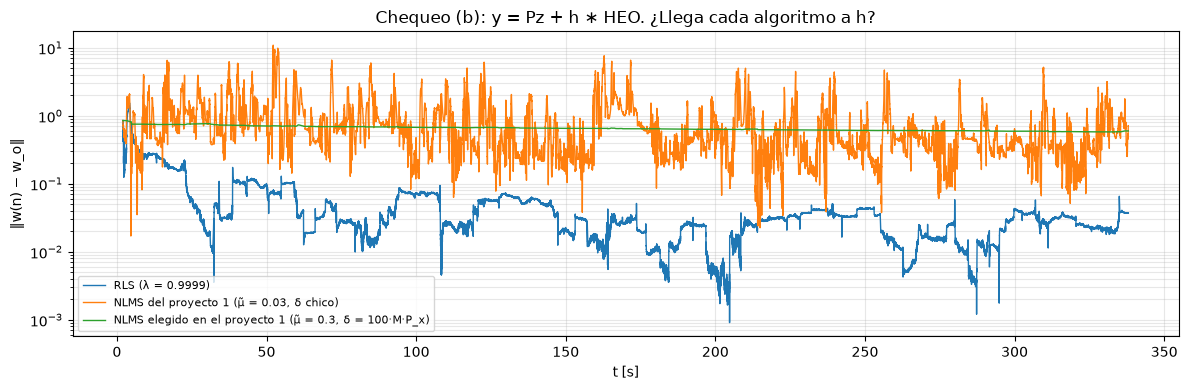

In [9]:
fig, ax = plt.subplots(figsize=(12, 4))
for nombre, W in curvas_b.items():
    ax.semilogy(t, np.linalg.norm(W - wi["w_o"], axis=1), lw=1, label=nombre)
ax.set_xlabel("t [s]")
ax.set_ylabel("‖w(n) − w_o‖")
ax.set_title("Chequeo (b): y = Pz + h ∗ HEO. ¿Llega cada algoritmo a h?")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Qué mirar: sanity check
- **(a) pasa:** `w(N) = [0.8, −0.3, 0.099]`, igual a `w_o` en tres decimales. **Llega a menos del 10 % de `h` en la muestra 14**: es el orden de `2M` que dice el PDF para SNR alto. NLMS, con la misma prueba en el proyecto 1, terminaba en `[0.776, −0.299, 0.12]` después de 20 000 muestras.
- **(b) pasa, y es la diferencia más grande con el proyecto 1:**

  | `y = Pz + h ∗ HEO` (spread 2685) | `w(N)` | `‖w(N) − w_o‖` |
  |---|---|---|
  | `w_o` | `[0.798, −0.281, 0.119]` | — |
  | **RLS `λ = 0.9999`** | `[0.766, −0.283, 0.140]` | **0.038** |
  | NLMS del proyecto 1 (`δ` chico) | `[0.352, −0.784, −0.097]` | 0.706 |
  | NLMS elegido en el proyecto 1 | `[0.352, 0.080, −0.058]` | 0.601 |

  - En el gráfico, RLS baja de 0.1 a los ~30 s y después se queda entre 0.01 y 0.1. Ninguno de los dos NLMS baja de ~0.6 en 336 s: el NLMS elegido es estable, pero sus modos lentos no llegan.
  - **Confirma la hipótesis: la convergencia de RLS no depende del spread.** RLS multiplica por `P(n) ≈ R⁻¹`, que "blanquea" la entrada: todos los modos convergen a la misma velocidad.
  - **Que no baje a 0 es lo esperado con `λ < 1`.** El PDF dice que la correlación del error de coeficientes tiende a `K(∞) ≈ (1−λ)/(1+λ)·E_o·R⁻¹`, que no es cero (memoria finita). Además se agranda con el autovalor más chico de `R` (4.6), y por eso las fluctuaciones.
- **(c) pasa:** con `λ = 1`, `w(N) = [0.7977, −0.2812, 0.1194]`, idéntico a Wiener con toda la señal en 4 decimales. El código hace LS exacto. `α(n)` queda siempre en `(0, 1]` (mínimo 0.0003, en el parpadeo más grande) y `P(N)` tiene autovalores positivos: no hay problemas numéricos.

### 3.3 Primera corrida sobre los datos reales
`procesar(canal)` corre RLS con `y` = el canal y `x` = `HEO`, y calcula Wiener sobre la misma señal para comparar. Es la función del proyecto 1, con `rls()` en lugar de `nlms()`.

**Metaparámetros:**
- `M = 3`, como en el proyecto 1.
- `λ = 0.9999`: memoria de 40 s, unos 9 parpadeos (§2.4).
- `δ = 0.01·σx²`: la inicialización del PDF. Todavía no está elegida: se barre en §5.

**Canales:** `Fp1` y `Fp2` (`β ≈ 0.4`), y `Pz` como control (`β ≈ 0.04`).

**La tabla** es la misma del proyecto 1: `w(N)` comparado con `w_o`, `J_min/P_y` (lo que no puede sacar ni el mejor filtro fijo), el spread de `R` y la correlación de `y` y de `e` con la referencia.

In [10]:
CANALES_Y = ["Fp1", "Fp2", "Pz"]                    # Los dos con más parpadeo y un control lejos de los ojos


def procesar(canal, lam=LAMBDA_RLS, delta_rel=DELTA_REL_RLS, M=M):
    """RLS con y = canal y x = HEO, más la solución de Wiener para comparar."""
    y, refs = DATOS[canal], [DATOS[CANAL_EOG]]
    e, y_hat, W = rls(y, refs, M, lam, delta_rel * np.mean(refs[0]**2))
    return {"y": y, "e": e, "y_hat": y_hat, "W": W, "wiener": wiener(y, refs, M)}


reales = {n: procesar(n) for n in CANALES_Y}

filas = {}
for n, r in reales.items():
    w_o = r["wiener"]["w_o"]
    filas[n] = {"w(N)": r["W"][-1].round(3), "w_o": w_o.round(3),
                "‖w(N)−w_o‖/‖w_o‖": np.linalg.norm(r["W"][-1] - w_o) / np.linalg.norm(w_o),
                "J_min / P_y": r["wiener"]["J_min"] / np.mean(r["y"]**2),
                "spread": r["wiener"]["spread"],
                "ρ(y, x)": np.corrcoef(r["y"], DATOS[CANAL_EOG])[0, 1],
                "ρ(e, x)": np.corrcoef(r["e"], DATOS[CANAL_EOG])[0, 1]}
print(pd.DataFrame(filas).T.to_string(float_format=lambda v: f"{v:.3g}"))

                      w(N)                     w_o ‖w(N)−w_o‖/‖w_o‖ J_min / P_y   spread ρ(y, x) ρ(e, x)
Fp1  [0.279, 0.043, 0.056]   [0.323, 0.041, 0.025]            0.165       0.433 2.68e+03   0.753 -0.0137
Fp2  [0.289, 0.044, 0.059]   [0.328, 0.048, 0.024]             0.16       0.444 2.68e+03   0.745  -0.013
Pz   [-0.034, 0.017, 0.04]  [-0.002, 0.019, 0.019]             1.39       0.992 2.68e+03  0.0896 -0.0172


### Qué mirar: RLS contra Wiener
- **Wiener es el mismo del proyecto 1:** `w_o ≈ [0.32, 0.04, 0.025]` en `Fp1` y `Fp2`, casi una ganancia de ~0.39 (`β ≈ 0.4`). `J_min/P_y` = 0.43 en `Fp1` y 0.99 en `Pz`.
- **RLS termina cerca de `w_o`:**
  - `Fp1`: `w(N) = [0.28, 0.04, 0.06]`, a 0.17 veces `‖w_o‖` (**el NLMS de la primera corrida del proyecto 1 estaba a 2.2 veces**);
  - `Fp2`: a 0.16 veces;
  - `Pz`: `w(N) = [−0.03, 0.02, 0.04]`. La distancia relativa da 1.39, pero porque `w_o ≈ 0`; en valor absoluto los coeficientes son chicos (en el proyecto 1 eran ~−0.45).
- **ρ(e, x) = −0.014 en `Fp1`** (en `y` era 0.75). Prácticamente 0, que es lo que dice el principio de ortogonalidad para `w_o`. En la primera corrida del proyecto 1 daba −0.13: restaba de más.
- `w(N)` es un solo instante. 3.5 muestra que `w(n)` no salta, así que esta vez sí se puede leer como "el valor al que llegó".

### 3.4 En el tiempo
El mismo tramo que en el proyecto 1 (de 40 a 55 s): `y`, `ŷ` y `e` en los tres canales, con los parpadeos marcados.

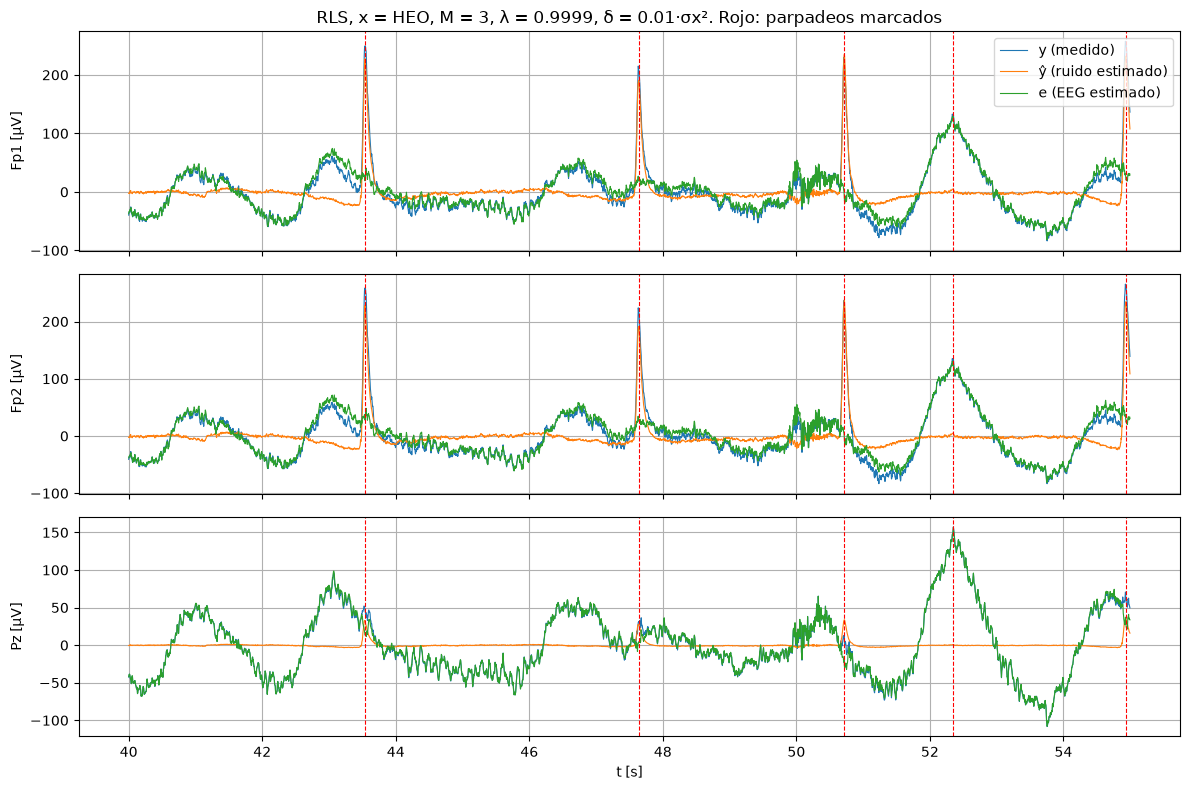

In [11]:
T_VER_3 = (40, 55)                                 # Tramo a mirar [s] (el mismo del proyecto 1)
i0, i1 = [int((tv - T_INI) * FS) for tv in T_VER_3]

fig, axs = plt.subplots(len(CANALES_Y), 1, figsize=(12, 8), sharex=True)
for ax, (n, r) in zip(axs, reales.items()):
    ax.plot(t[i0:i1], r["y"][i0:i1], label="y (medido)", lw=0.8)
    ax.plot(t[i0:i1], r["y_hat"][i0:i1], label="ŷ (ruido estimado)", lw=0.8)
    ax.plot(t[i0:i1], r["e"][i0:i1], label="e (EEG estimado)", lw=0.8)
    for k in PARPADEOS[(PARPADEOS >= i0) & (PARPADEOS < i1)]:
        ax.axvline(t[k], color="r", lw=0.8, ls="--")
    ax.set_ylabel(f"{n} [µV]")
    ax.grid(True)
axs[0].legend(loc="upper right")
axs[0].set_title(f"RLS, x = HEO, M = {M}, λ = {LAMBDA_RLS}, δ = {DELTA_REL_RLS}·σx². Rojo: parpadeos marcados")
axs[-1].set_xlabel("t [s]")
plt.tight_layout()
plt.show()

### Qué mirar: y, ŷ y e en el tiempo
- **En `Fp1` y `Fp2` los parpadeos se van.** En cada línea roja, `ŷ` copia el pico de `y` (~200–250 µV) y `e` queda al nivel del resto.
- **Entre parpadeos `ŷ` queda cerca de 0:** las oscilaciones de ±100 µV que tenía NLMS en la primera corrida del proyecto 1 (52–55 s) no están. Lo que se ve son desvíos lentos de −10 a −20 µV antes de algunos parpadeos (por ejemplo, 43 s y 51–52 s). Son ~0.4 veces lo que hace `HEO` en esos momentos (los lóbulos negativos del pasa-altos y movimientos lentos de ojos), así que el filtro los resta porque están en la referencia.
- **Las ondas lentas comunes quedan en `e`** (52–53 s): no están en `HEO`, como en el proyecto 1.
- **En `Pz`, `e` va encima de `y`:** `ŷ` tiene picos de ~20–30 µV en los parpadeos, lo que corresponde a `β ≈ 0.04` × ~500 µV. Ya no aparecen los picos de ±400 µV de la primera corrida del proyecto 1.

### 3.5 Los coeficientes en el tiempo
`w(n)` de los tres coeficientes para cada canal. En línea punteada del mismo color, el `w_o` de Wiener. A la derecha, la suma `w0 + w1 + w2` (la ganancia del camino) contra la suma de `w_o`: en el proyecto 1 convergía la suma, no cada coeficiente.

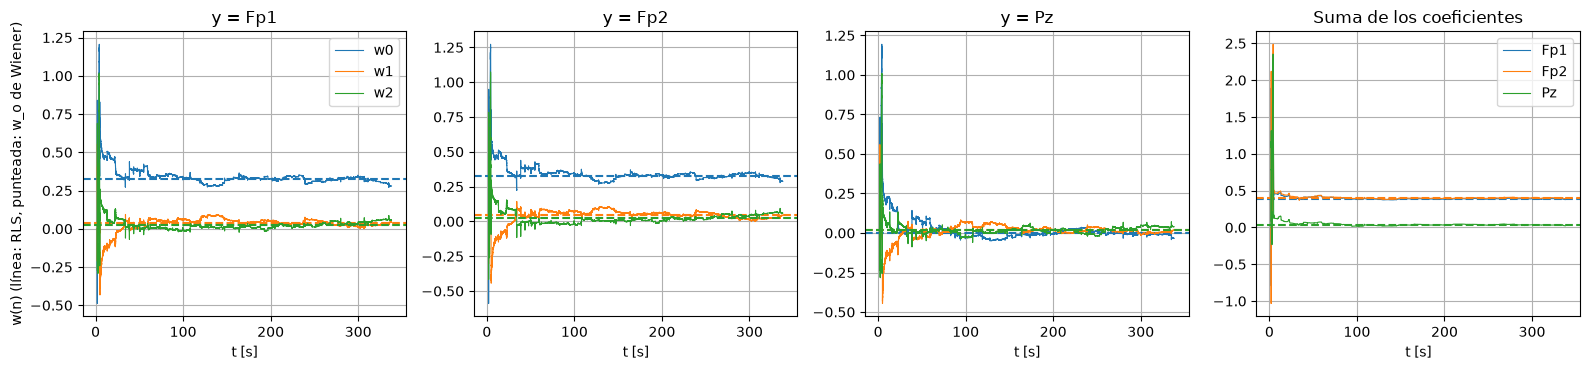

Fp1: w̄ (2.ª mitad) = [0.323 0.036 0.029]  w_o = [0.323 0.041 0.025]  std de w = 0.016  suma: 0.388 vs 0.390
Fp2: w̄ (2.ª mitad) = [0.328 0.041 0.03 ]  w_o = [0.328 0.048 0.024]  std de w = 0.017  suma: 0.399 vs 0.399
Pz: w̄ (2.ª mitad) = [0.001 0.014 0.022]  w_o = [-0.002  0.019  0.019]  std de w = 0.015  suma: 0.037 vs 0.036


In [12]:
fig, axs = plt.subplots(1, len(CANALES_Y) + 1, figsize=(16, 3.8), sharex=True)
for ax, (n, r) in zip(axs, reales.items()):
    for i in range(M):
        linea, = ax.plot(t, r["W"][:, i], label=f"w{i}", lw=0.8)
        ax.axhline(r["wiener"]["w_o"][i], color=linea.get_color(), ls="--")
    ax.set_title(f"y = {n}")
    ax.set_xlabel("t [s]")
    ax.grid(True)
for n, r in reales.items():
    linea, = axs[-1].plot(t, r["W"].sum(axis=1), lw=0.8, label=n)
    axs[-1].axhline(r["wiener"]["w_o"].sum(), color=linea.get_color(), ls="--")
axs[-1].set_title("Suma de los coeficientes")
axs[-1].set_xlabel("t [s]")
axs[-1].grid(True)
axs[-1].legend()
axs[0].set_ylabel("w(n) (línea: RLS, punteada: w_o de Wiener)")
axs[0].legend()
plt.tight_layout()
plt.show()

for n, r in reales.items():
    W2 = r["W"][len(r["W"]) // 2:]                  # Segunda mitad
    print(f"{n}: w̄ (2.ª mitad) = {W2.mean(axis=0).round(3)}  w_o = {r['wiener']['w_o'].round(3)}  "
          f"std de w = {W2.std(axis=0).mean():.3f}  suma: {W2.sum(axis=1).mean():.3f} vs {r['wiener']['w_o'].sum():.3f}")

### Qué mirar: los coeficientes
- **El arranque (primeros ~10 s):** los coeficientes saltan hasta ~1.2 y −0.5. Es la ventana llenándose (§2.5): al principio `R̂(n)` tiene pocos datos y la ganancia es grande. Después de ~50 s ya están cerca de `w_o`. **Esto depende de `δ`**, que acá es el de libro (0.01·σx²): se elige en §5.
- **Después, cada coeficiente llega a su `w_o`:**

  | Segunda mitad | `w̄` | `w_o` | suma: `w̄` / `w_o` | std de `w` |
  |---|---|---|---|---|
  | `Fp1` | `[0.323, 0.036, 0.029]` | `[0.323, 0.041, 0.025]` | 0.388 / 0.390 | 0.016 |
  | `Fp2` | `[0.328, 0.041, 0.030]` | `[0.328, 0.048, 0.024]` | 0.399 / 0.399 | 0.017 |
  | `Pz` | `[0.001, 0.014, 0.022]` | `[−0.002, 0.019, 0.019]` | 0.037 / 0.036 | 0.015 |

- **En el proyecto 1, el NLMS elegido llegaba a la suma pero no a cada coeficiente:** `w ≈ [0.20, 0.13, 0.05]` contra `w_o = [0.32, 0.04, 0.025]`, por el spread (2685). **RLS resuelve eso**, como en el chequeo (b).
- **Tiembla igual o menos que el NLMS elegido** (std 0.016 contra 0.02), así que llegar a cada coeficiente no le cuesta más ruido en `w`.

### 3.6 ¿Desaparece el parpadeo? (promedio sincronizado de y y e)
La prueba principal del proyecto 1: el promedio sincronizado de 2.2, sobre `y` y sobre `e`. Si el filtro saca el parpadeo, la curva de `e` tiene que quedar plana. La tabla da el pico a pico de cada promedio y cuánto bajó, en dB.

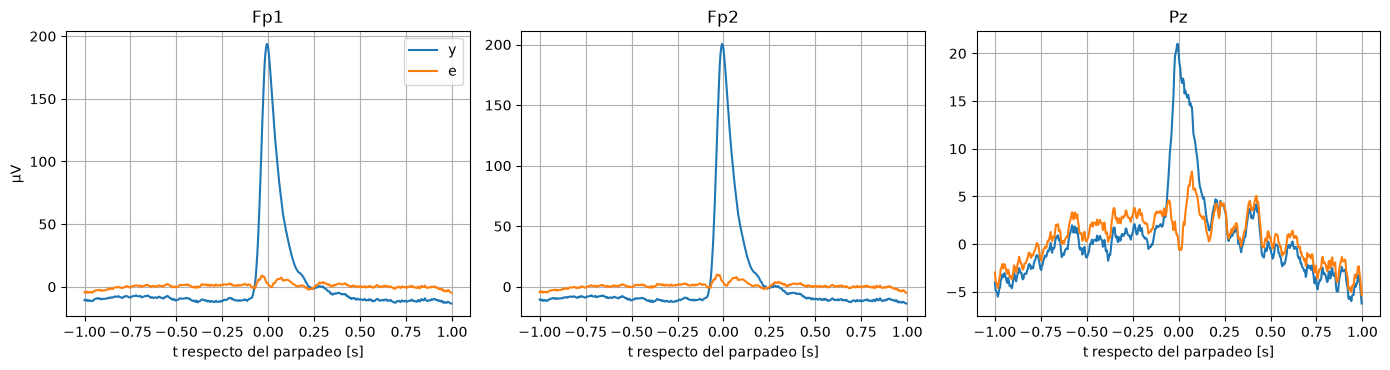

     pico a pico y [µV]  pico a pico e [µV]  reducción [dB]
Fp1               207.1                13.8           -23.5
Fp2               214.3                14.9           -23.1
Pz                 27.2                13.0            -6.4


In [13]:
fig, axs = plt.subplots(1, len(CANALES_Y), figsize=(14, 3.8))
filas = {}
for ax, (n, r) in zip(axs, reales.items()):
    py, pe = promedio_sincronizado(r["y"], PARPADEOS), promedio_sincronizado(r["e"], PARPADEOS)
    ax.plot(tau, py, label="y")
    ax.plot(tau, pe, label="e")
    ax.set_title(n)
    ax.set_xlabel("t respecto del parpadeo [s]")
    ax.grid(True)
    filas[n] = {"pico a pico y [µV]": np.ptp(py), "pico a pico e [µV]": np.ptp(pe),
                "reducción [dB]": 20 * np.log10(np.ptp(pe) / np.ptp(py))}
axs[0].set_ylabel("µV")
axs[0].legend()
plt.tight_layout()
plt.show()
print(pd.DataFrame(filas).T.round(1).to_string())

### Qué mirar: el parpadeo promedio en y y en e
- **En `Fp1` y `Fp2` el pico baja de ~210 a ~14 µV pico a pico: −23.5 dB.** En la primera corrida del proyecto 1 bajaba −14.4 dB y quedaba un pozo de −35 µV. **Ahora no hay pozo:** queda un resto de ~+8 µV en t = 0, sin cambio de signo.
- **La línea de base de `e` queda en 0, y la de `y` estaba en ~−10 µV.** El lóbulo negativo que el pasa-altos le agrega al parpadeo también está en `HEO`, así que el filtro lo saca junto con el parpadeo.
- **En `Pz`:** el pico baja de 21 a ~7 µV y no se da vuelta (en el proyecto 1 pasaba de +21 a −14 µV). La reducción de −6.4 dB es real: queda la forma del EEG de fondo.

### 3.7 ¿Se daña el EEG fuera de los parpadeos?
Igual que en el proyecto 1: la potencia de `e` contra la de `y`, en dB (0 = no cambió; negativo = el filtro sacó; positivo = agregó), en tres lugares:
- 0.5–8 Hz **con** parpadeo, donde queremos que baje;
- 0.5–8 Hz **sin** parpadeo, donde queremos que no cambie;
- α (8–13 Hz) sin parpadeo: el EEG que menos queremos tocar.

La última columna es `RRMSE(e, y)` fuera de los parpadeos: si el filtro no hace nada ahí, da ~0. "Con parpadeo" son las muestras a menos de 0.5 s de una marca; "sin parpadeo", el resto.

In [14]:
MARGEN = int(0.5 * FS)                             # Margen alrededor de cada parpadeo [muestras]
con_parpadeo = np.zeros(N_MUESTRAS, bool)
for k in PARPADEOS:
    con_parpadeo[max(k - MARGEN, 0):k + MARGEN] = True
limpio = ~con_parpadeo                             # Muestras a más de 0.5 s de cualquier parpadeo

sos_08 = butter(4, [F_HP, 8], "bandpass", fs=FS, output="sos")
sos_alfa = butter(4, [8, 13], "bandpass", fs=FS, output="sos")


def potencia(x, sos, mascara):
    """Potencia de x filtrada con sos, solo en las muestras de la máscara."""
    return np.mean(sosfiltfilt(sos, x)[mascara]**2)


def db(a, b):
    return 10 * np.log10(a / b)


filas = {}
for n, r in reales.items():
    filas[n] = {"0.5-8 Hz con parpadeo [dB]": db(potencia(r["e"], sos_08, con_parpadeo), potencia(r["y"], sos_08, con_parpadeo)),
                "0.5-8 Hz sin parpadeo [dB]": db(potencia(r["e"], sos_08, limpio), potencia(r["y"], sos_08, limpio)),
                "α sin parpadeo [dB]": db(potencia(r["e"], sos_alfa, limpio), potencia(r["y"], sos_alfa, limpio)),
                "RRMSE(e, y) sin parpadeo": rrmse(r["e"][limpio], r["y"][limpio])}
print("Cambio de potencia de e respecto de y (0 dB = no cambió; negativo = el filtro sacó):")
print(pd.DataFrame(filas).T.round(2).to_string())

Cambio de potencia de e respecto de y (0 dB = no cambió; negativo = el filtro sacó):
     0.5-8 Hz con parpadeo [dB]  0.5-8 Hz sin parpadeo [dB]  α sin parpadeo [dB]  RRMSE(e, y) sin parpadeo
Fp1                      -14.06                       -1.32                -1.05                      0.33
Fp2                      -13.91                       -1.28                -1.10                      0.32
Pz                        -0.56                        0.02                -0.06                      0.08


### Qué mirar: daño al EEG
- **Con parpadeo, 0.5–8 Hz baja −14.1 dB en `Fp1`** (el NLMS elegido del proyecto 1: −13.0 dB; Wiener: −14.2 dB).
- **Sin parpadeo casi no toca:** α −1.05 dB y `RRMSE(e, y)` = 0.33. Son los números del NLMS elegido y de Wiener en el proyecto 1 (α −1.0 dB, RRMSE 0.31–0.32). La baja de 1 dB en α ya la tenía Wiener, así que viene de los datos (EEG frontal que ve `HEO`, o movimientos chicos de ojos), no del algoritmo.
- **En 0.5–8 Hz sin parpadeo baja −1.3 dB:** lo que el filtro resta entre parpadeos son los desvíos lentos de `HEO` de 3.4.
- **`Pz` (control) queda intacto:** cambios de −0.6 a 0 dB y `RRMSE(e, y)` = 0.08 (NLMS elegido: 0.07).

### Para discutir
**Lo que salió:**
- **RLS con `λ = 0.9999` anda en la primera corrida,** sin barrer nada: −23.5 dB en el parpadeo promedio, el control intacto, y el EEG sin parpadeos tocado igual que con Wiener.
- **Llega a cada coeficiente, no solo a la suma:** `w̄ = [0.323, 0.036, 0.029]` contra `w_o = [0.323, 0.041, 0.025]`. NLMS y LMS no podían por el spread de 2685; RLS no depende del spread (chequeo (b)).
- **Por eso saca más pico que el NLMS elegido:** queda un resto de ~10 µV contra ~22 µV (4.2).

**Preguntas abiertas:**
1. **¿`λ = 0.9999` es necesario, o cualquier `λ` sirve?** La hipótesis de §2 dice que un `λ` chico tendría que fallar como NLMS con `δ` chico → §4.
2. **El arranque:** los primeros ~10 s los coeficientes saltan hasta 1.2. ¿Lo arregla un `δ` más grande, como sugiere Moustakides para SNR bajo? → §5.
3. **¿Entre 0.999 y 0.9999, cuál?** Sin ground truth no se puede decidir bien → semi-sintético, §5.
4. **¿Le gana a LMS en condiciones parecidas?** Es lo que pide el enunciado → §5.

## §4. Diagnóstico: ¿qué hace `λ`?

> **Dónde estamos:** en §2.5 predijimos que, como RLS normaliza por la potencia de `HEO` promediada con su ventana, un `λ` chico debería fallar igual que NLMS con `δ` chico en el proyecto 1. En §3 corrimos `λ = 0.9999`. Ahora hay que confirmar que la elección importa, y por qué.
>
> Pasos (los de §4 del proyecto 1):
> 1. El paso efectivo de RLS con distintos `λ`, junto a `‖x(n)‖²` y al paso de NLMS.
> 2. Las variantes sobre los datos reales: RLS con `λ` = 0.99, 0.999 y 0.9999, contra NLMS con `δ` chico (la primera corrida del proyecto 1), el NLMS elegido y el mejor LMS del proyecto 1.
> 3. Los coeficientes de cada variante.

### 4.1 La energía de la referencia y el paso efectivo
En NLMS, `Δw = μ(n)·x(n)·e(n)` con `μ(n) = μ̃ / (‖x(n)‖² + δ)`. En RLS, `Δw = g(n)·e(n)`, y su paso en la dirección de `x` es `μ_ef(n) = xᵀg / ‖x‖²`. Se puede ver que `xᵀg = 1 − α(n)`, así que `μ_ef(n) = (1 − α(n)) / ‖x(n)‖²`: **RLS es un NLMS cuyo `μ̃` cambia en cada muestra entre 0 y 1**, según cuánto pesa `x(n)` frente a lo que ya tiene en `R̂(n)`.

La celda corre RLS sobre `Fp1` con tres `λ` y dibuja, en 60 s:
- arriba, `‖x(n)‖²`;
- en el medio, el paso efectivo: `μ_ef(n)` de cada RLS, junto con el `μ(n)` de NLMS con `δ` chico (§3 del proyecto 1) y del NLMS elegido;
- abajo, **lo que realmente se mueve `w`** en cada muestra, `‖Δw(n)‖ = ‖w(n+1) − w(n)‖`. El paso solo no alcanza: la corrección es paso × `x` × `e` (proyecto 1, §4: "la llave está en `x·e`").

El paso de RLS cambia muchísimo de una muestra a otra (depende de hacia dónde apunta `x(n)`, ver "Qué mirar"), así que las curvas del medio y de abajo están **suavizadas con una media geométrica de 0.2 s** para que se puedan leer. Las tablas usan los valores sin suavizar.

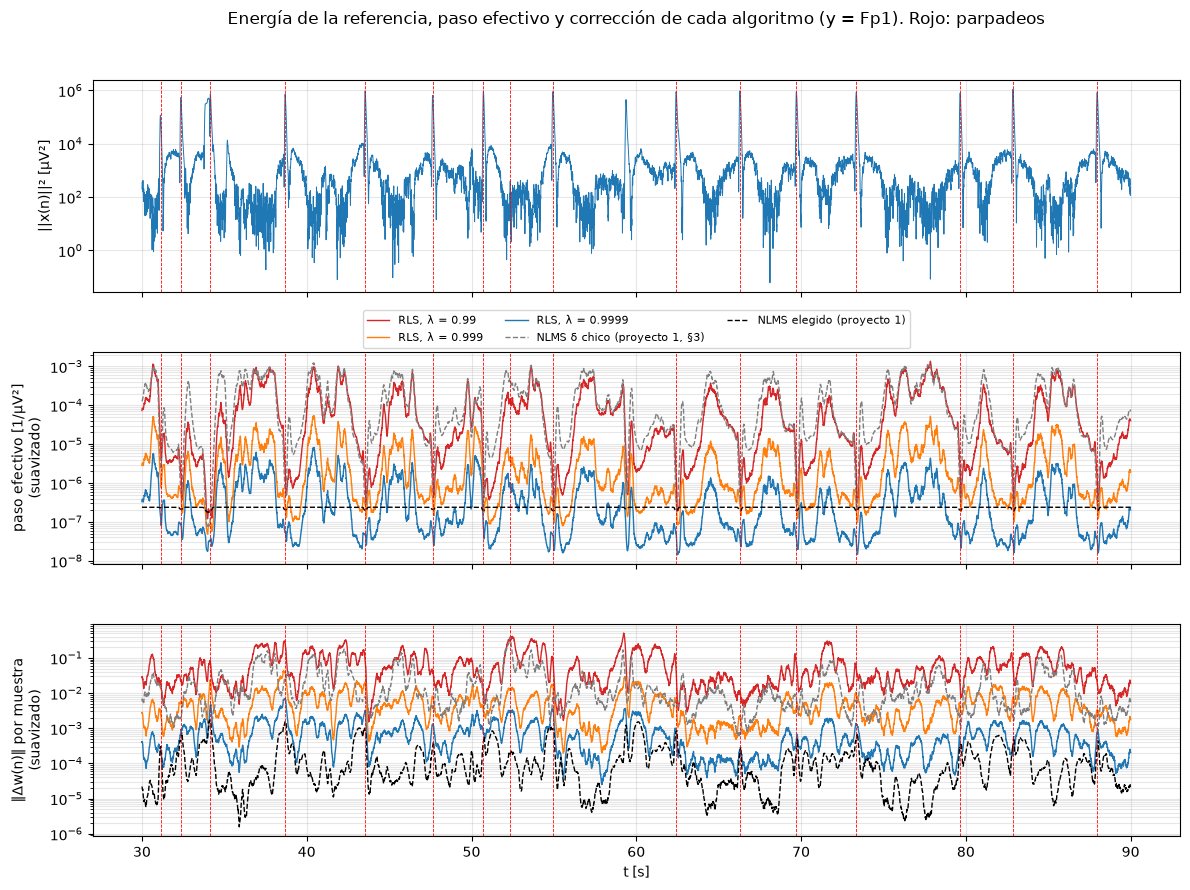

Paso efectivo mediano [1/µV²] y recorrido total de w (Σ‖Δw‖), sin los primeros 40 s:
                               paso sin parpadeo  paso en el pico  Σ‖Δw‖ sin parpadeo  Σ‖Δw‖ con parpadeo  % de Σ‖Δw‖ sin parpadeo
RLS, λ = 0.99                            5.2e-05          3.5e-07             3.5e+03             8.3e+02                       81
RLS, λ = 0.999                           1.7e-06          8.7e-08             2.9e+02                  97                       75
RLS, λ = 0.9999                          1.7e-07          9.1e-09                  33                  12                       74
NLMS δ chico (proyecto 1, §3)            8.2e-05          3.8e-08             1.2e+03             1.8e+02                       87
NLMS elegido (proyecto 1)                2.4e-07          1.5e-07                 4.9                 5.1                       49

(Sin parpadeo es el 77 % de las muestras)


In [15]:
LAMBDAS_DIAG = [0.99, 0.999, 0.9999]
norma2 = np.convolve(DATOS[CANAL_EOG]**2, np.ones(M))[:N_MUESTRAS]       # ||x(n)||²


def suavizar_log(v, largo=FS // 5):
    """Media geométrica móvil (promedio en escala log), para dibujar curvas que saltan órdenes de magnitud."""
    return 10**np.convolve(np.log10(np.maximum(v, 1e-30)), np.ones(largo) / largo, mode="same")


paso, correccion = {}, {}
for lam in LAMBDAS_DIAG:
    _, _, W, mu_ef, alfa, _ = rls(DATOS["Fp1"], [DATOS[CANAL_EOG]], M, lam, DELTA_REL_RLS * P_X, diag=True)
    paso[f"RLS, λ = {lam}"] = mu_ef
    correccion[f"RLS, λ = {lam}"] = np.r_[np.linalg.norm(np.diff(W, axis=0), axis=1), 0]
for nombre, mu_t, d in [("NLMS δ chico (proyecto 1, §3)", 0.03, 1e-3), ("NLMS elegido (proyecto 1)", 0.3, 100)]:
    paso[nombre] = mu_t / (norma2 + d * M * P_X)
    _, _, W = nlms(DATOS["Fp1"], [DATOS[CANAL_EOG]], M, mu_t, d * M * P_X)
    correccion[nombre] = np.r_[np.linalg.norm(np.diff(W, axis=0), axis=1), 0]

i0, i1 = [int((tv - T_INI) * FS) for tv in T_VER]
colores = {"RLS, λ = 0.99": "tab:red", "RLS, λ = 0.999": "tab:orange", "RLS, λ = 0.9999": "tab:blue",
           "NLMS δ chico (proyecto 1, §3)": "tab:gray", "NLMS elegido (proyecto 1)": "k"}
fig, axs = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axs[0].semilogy(t[i0:i1], norma2[i0:i1], lw=0.7)
axs[0].set_ylabel("||x(n)||² [µV²]")
for nombre in paso:
    estilo = dict(lw=1, color=colores[nombre], ls="--" if "NLMS" in nombre else "-")
    axs[1].semilogy(t[i0:i1], suavizar_log(paso[nombre])[i0:i1], label=nombre, **estilo)
    axs[2].semilogy(t[i0:i1], suavizar_log(correccion[nombre])[i0:i1], **estilo)
axs[1].set_ylabel("paso efectivo [1/µV²]\n(suavizado)")
axs[2].set_ylabel("‖Δw(n)‖ por muestra\n(suavizado)")
axs[1].legend(fontsize=8, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.22))
for ax in axs:
    for k in PARPADEOS[(PARPADEOS >= i0) & (PARPADEOS < i1)]:
        ax.axvline(t[k], color="r", lw=0.6, ls="--")
    ax.grid(True, which="both", alpha=0.3)
axs[0].set_title("Energía de la referencia, paso efectivo y corrección de cada algoritmo (y = Fp1). Rojo: parpadeos",
                 pad=40)
axs[2].set_xlabel("t [s]")
plt.tight_layout()
plt.show()

# Tablas sin suavizar, después de los primeros 40 s (el arranque de λ = 0.9999)
desde = 40 * FS
sin_p = limpio.copy(); sin_p[:desde] = False
con_p = con_parpadeo.copy(); con_p[:desde] = False
picos = PARPADEOS[PARPADEOS >= desde]
tabla_paso = pd.DataFrame({nombre: {"paso sin parpadeo": np.median(paso[nombre][sin_p]),
                                    "paso en el pico": np.median(paso[nombre][picos]),
                                    "Σ‖Δw‖ sin parpadeo": correccion[nombre][sin_p].sum(),
                                    "Σ‖Δw‖ con parpadeo": correccion[nombre][con_p].sum()}
                           for nombre in paso}).T
tabla_paso["% de Σ‖Δw‖ sin parpadeo"] = 100 * tabla_paso["Σ‖Δw‖ sin parpadeo"] / (
    tabla_paso["Σ‖Δw‖ sin parpadeo"] + tabla_paso["Σ‖Δw‖ con parpadeo"])
print("Paso efectivo mediano [1/µV²] y recorrido total de w (Σ‖Δw‖), sin los primeros 40 s:")
print(tabla_paso.to_string(float_format=lambda v: f"{v:.2g}"))
print(f"\n(Sin parpadeo es el {100 * sin_p[desde:].mean():.0f} % de las muestras)")

### Qué mirar: la energía de la referencia y el paso
- **En el medio, RLS con `λ = 0.99` (rojo) va pegado a NLMS con `δ` chico (gris):** paso de ~10⁻⁴ a 10⁻³ entre parpadeos, y mínimo en los picos. En la tabla, el paso mediano sin parpadeo es 5.2·10⁻⁵ contra 8.2·10⁻⁵ de NLMS, y **150 veces más grande que en el pico.** Es la predicción de §2.5: con 0.4 s de memoria, RLS normaliza casi como NLMS.
- **Con `λ = 0.999` y `0.9999` el paso baja 30 y 300 veces,** pero sigue siendo ~20 veces más grande entre parpadeos que en el pico. **Esto ya no es la ventana:** con `λ = 0.9999`, `R̂(n)` es casi constante (§2.5). Es la dirección de `x(n)`:
  - en un parpadeo, `HEO(n)`, `HEO(n−1)` y `HEO(n−2)` son casi iguales: `x` apunta a `[1, 1, 1]`, el autovector de `R` con el autovalor más grande, y `xᵀPx/‖x‖² ≈ 1/λmax`;
  - entre parpadeos, `HEO` tiene fluctuaciones rápidas y `x` tiene componente en las direcciones de autovalores chicos (las diferencias entre coeficientes), donde `P = R⁻¹` es grande.
  
  **Es el blanqueo de RLS: da pasos grandes justo en los modos lentos.** Por eso llega a cada coeficiente, y LMS/NLMS no. Es el mismo mecanismo del chequeo (b), visto desde el paso.
- **Abajo, lo que se mueve `w`:** RLS con `λ = 0.99` recorre 3500 (suma de `‖Δw‖`), más que NLMS con `δ` chico (1200). Con `λ = 0.9999`, 33: cien veces menos. El NLMS elegido, 4.9.
- **Un detalle honesto:** aun con `λ = 0.9999`, el 74 % del recorrido de `w` pasa entre parpadeos (que son el 77 % de las muestras), contra el 49 % del NLMS elegido. RLS sigue aprendiendo entre parpadeos, pero con pasos chicos: la std de `w` es 0.016 (3.5).

### 4.2 Las variantes sobre los datos reales
Dos funciones del proyecto 1, con RLS agregado:
- **`correr()`** corre cualquiera de los algoritmos con metaparámetros comparables: para NLMS, `δ = δ_rel·M·P_x`; para LMS, `μ = μ̃ / (M·P_x)`; para RLS, `λ` y `δ = δ_rel·σx²`.
- **`pruebas_reales()`** junta las pruebas de §3 en un diccionario: `‖w̄ − w_o‖` y `std de w` en la segunda mitad de la grabación, el pico del parpadeo promedio en `y` y en `e`, la potencia en 0.5–8 Hz con parpadeo, α sin parpadeo y `RRMSE(e, y)` sin parpadeo.

**Las variantes** (todas sobre `Fp1` y `Pz`):

| Variante | Metaparámetros | De dónde sale |
|---|---|---|
| RLS `λ = 0.99` | `δ = 0.01·σx²` | El `λ` "de libro" |
| RLS `λ = 0.999` | `δ = 0.01·σx²` | Memoria de 4 s, ≈ un parpadeo |
| RLS `λ = 0.9999` | `δ = 0.01·σx²` | El de §3 |
| NLMS `δ` chico | `μ̃ = 0.03`, `δ = 10⁻³·M·P_x` | La primera corrida del proyecto 1 |
| NLMS elegido | `μ̃ = 0.3`, `δ = 100·M·P_x` | Lo elegido en el proyecto 1 |
| LMS | `μ̃ = 0.001` | El mejor LMS del semi-sintético del proyecto 1 |

In [16]:
def correr(algoritmo, y, refs, M=3, mu_t=None, delta_rel=None, lam=None):
    """Corre "RLS", "NLMS" o "LMS" con metaparámetros comparables entre ellos."""
    traza = M * sum(np.mean(r**2) for r in refs)     # tr R = M · P_x
    with np.errstate(all="ignore"):                  # LMS puede divergir: que dé nan sin avisar
        if algoritmo == "RLS":
            return rls(y, refs, M, lam, delta_rel * traza / M)
        if algoritmo == "LMS":
            return lms(y, refs, M, mu_t / traza)
        return nlms(y, refs, M, mu_t, delta_rel * traza)


def pruebas_reales(y, e, W, w_o):
    """Las pruebas de §3 (sin ground truth) en un solo diccionario."""
    py, pe = promedio_sincronizado(y, PARPADEOS), promedio_sincronizado(e, PARPADEOS)
    base = slice(0, VENTANA // 2)                    # De -1 a -0.5 s: nivel de base del promedio
    cerca = slice(VENTANA - FS // 10, VENTANA + FS // 10)   # ±0.1 s alrededor del pico marcado
    pico_y, pico_e = py[cerca] - py[base].mean(), pe[cerca] - pe[base].mean()
    mitad = len(W) // 2                              # Segunda mitad de la grabación
    with np.errstate(all="ignore"):
        return {"‖w̄ − w_o‖": np.linalg.norm(W[mitad:].mean(axis=0) - w_o),
                "std de w": W[mitad:].std(axis=0).mean(),
                "parpadeo y [µV]": pico_y[np.argmax(np.abs(pico_y))],
                "parpadeo e [µV]": pico_e[np.argmax(np.abs(pico_e))],
                "0.5-8 Hz con parp. [dB]": db(potencia(e, sos_08, con_parpadeo), potencia(y, sos_08, con_parpadeo)),
                "α sin parp. [dB]": db(potencia(e, sos_alfa, limpio), potencia(y, sos_alfa, limpio)),
                "RRMSE(e, y) sin parp.": rrmse(e[limpio], y[limpio])}


VARIANTES = {"RLS λ = 0.99": dict(algoritmo="RLS", lam=0.99, delta_rel=DELTA_REL_RLS),
             "RLS λ = 0.999": dict(algoritmo="RLS", lam=0.999, delta_rel=DELTA_REL_RLS),
             "RLS λ = 0.9999": dict(algoritmo="RLS", lam=0.9999, delta_rel=DELTA_REL_RLS),
             "NLMS δ chico": dict(algoritmo="NLMS", mu_t=0.03, delta_rel=1e-3),
             "NLMS elegido": dict(algoritmo="NLMS", mu_t=0.3, delta_rel=100),
             "LMS": dict(algoritmo="LMS", mu_t=0.001)}

diag, filas = {}, {}
for canal in ["Fp1", "Pz"]:
    w_o = reales[canal]["wiener"]["w_o"]
    for nombre, kw in VARIANTES.items():
        e, _, W = correr(y=DATOS[canal], refs=[DATOS[CANAL_EOG]], M=M, **kw)
        diag[(canal, nombre)] = (e, W)
        filas[(canal, nombre)] = pruebas_reales(DATOS[canal], e, W, w_o)

tabla_diag = pd.DataFrame(filas).T
tabla_diag.index.names = ["canal", "algoritmo"]
print(tabla_diag.round(2).to_string())

                      ‖w̄ − w_o‖  std de w  parpadeo y [µV]  parpadeo e [µV]  0.5-8 Hz con parp. [dB]  α sin parp. [dB]  RRMSE(e, y) sin parp.
canal algoritmo                                                                                                                               
Fp1   RLS λ = 0.99          0.06      0.23           202.53             8.50                   -10.82             -0.29                   0.49
      RLS λ = 0.999         0.02      0.06           202.53            11.37                   -13.82             -1.03                   0.33
      RLS λ = 0.9999        0.01      0.02           202.53             9.73                   -14.06             -1.05                   0.33
      NLMS δ chico          0.14      0.42           202.53           -36.47                    -0.32              1.84                   0.86
      NLMS elegido          0.14      0.02           202.53            21.64                   -12.97             -0.97                   0.31

### Qué mirar: las variantes sobre los datos reales
- **`λ = 0.99` falla, como se predijo en §2.5,** aunque menos que NLMS con `δ` chico:

  | `Fp1` | RLS 0.99 | RLS 0.999 | **RLS 0.9999** | NLMS `δ` chico | NLMS elegido | LMS |
  |---|---|---|---|---|---|---|
  | std de `w` | 0.23 | 0.06 | **0.02** | 0.42 | 0.02 | 0.01 |
  | `‖w̄ − w_o‖` | 0.06 | 0.02 | **0.01** | 0.14 | 0.14 | 0.18 |
  | parpadeo en `e` (en `y`: 203 µV) | +8.5 | +11.4 | **+9.7** | −36.5 | +21.6 | +24.7 |
  | 0.5–8 Hz con parpadeo [dB] | −10.8 | −13.8 | **−14.1** | −0.3 | −13.0 | −13.2 |
  | α sin parpadeo [dB] | −0.3 | −1.0 | **−1.05** | +1.8 | −1.0 | −1.0 |
  | `RRMSE(e, y)` sin parpadeo | 0.49 | 0.33 | **0.33** | 0.86 | 0.31 | 0.31 |

- **`λ = 0.99`:** el parpadeo promedio se va (+8.5 µV), pero **agrega ruido**: `w` tiembla 0.23, `RRMSE(e, y)` sin parpadeo sube a 0.49, y en `Pz` (control) **agrega +3.1 dB** en 0.5–8 Hz con `RRMSE` 0.42. Es la misma falla que NLMS con `δ` chico, más suave: estima la potencia con 99 muestras en lugar de 3.
- **`λ = 0.999` y `0.9999` dan casi lo mismo en los datos reales.** 0.9999 tiembla menos (0.02 contra 0.06) y queda más cerca de `w_o` (0.01 contra 0.02). Para decidir entre ellos hace falta saber la respuesta: §5.
- **Contra el proyecto 1:** RLS 0.9999 empata al NLMS elegido y a LMS fuera de los parpadeos (α −1.0 dB, `RRMSE` 0.31–0.33), y **saca más del pico (resto +9.7 µV contra +22 y +25)**, porque llega a cada coeficiente (`‖w̄ − w_o‖` = 0.01 contra 0.14 y 0.18).
- **En `Pz`, 0.999 y 0.9999 no lo tocan** (`RRMSE` 0.08, como el NLMS elegido 0.07 y LMS 0.04).

### 4.3 Los coeficientes de las variantes
`w(n)` en `Fp1` para las tres variantes de RLS y el NLMS elegido, todos con la misma escala (−2 a 2). La punteada es `w_o`.

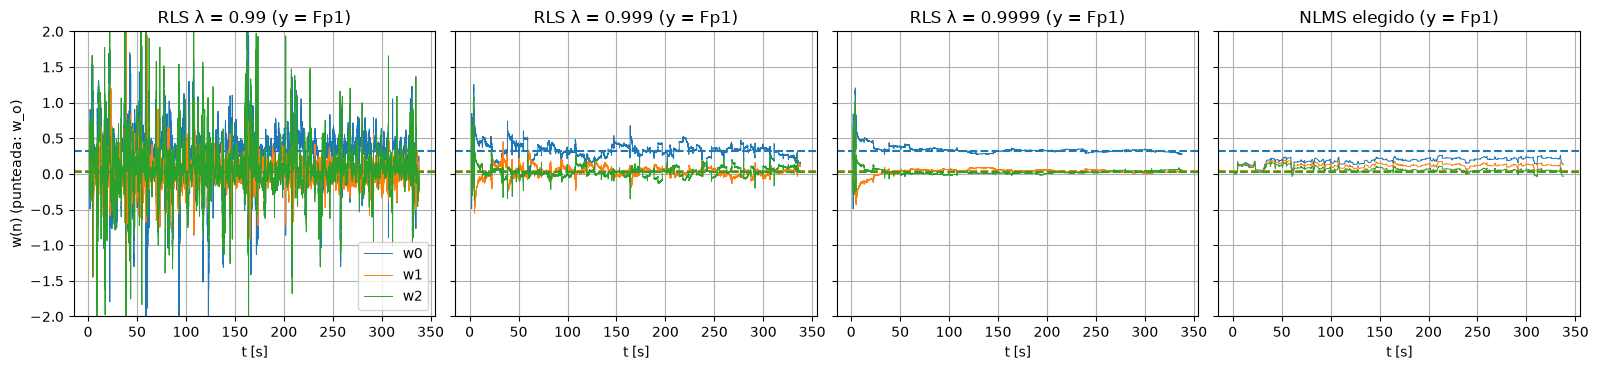

In [17]:
VER_COEF = ["RLS λ = 0.99", "RLS λ = 0.999", "RLS λ = 0.9999", "NLMS elegido"]
fig, axs = plt.subplots(1, len(VER_COEF), figsize=(16, 3.8), sharey=True)
w_o = reales["Fp1"]["wiener"]["w_o"]
for ax, nombre in zip(axs, VER_COEF):
    _, W = diag[("Fp1", nombre)]
    for i in range(M):
        linea, = ax.plot(t, W[:, i], lw=0.7, label=f"w{i}")
        ax.axhline(w_o[i], color=linea.get_color(), ls="--")
    ax.set_title(f"{nombre} (y = Fp1)")
    ax.set_xlabel("t [s]")
    ax.grid(True)
axs[0].set_ylabel("w(n) (punteada: w_o)")
axs[0].set_ylim(-2, 2)
axs[0].legend()
plt.tight_layout()
plt.show()

### Qué mirar: los coeficientes
- **`λ = 0.99`:** los coeficientes llenan la escala de −2 a 2 todo el tiempo. Es la figura de NLMS con `δ` chico del proyecto 1.
- **`λ = 0.999`:** se mueven alrededor de `w_o` (±0.2 en `w0`), con escalones en cada parpadeo.
- **`λ = 0.9999`:** después del arranque son casi rectas y **están sobre las punteadas**: cada coeficiente en su `w_o`.
- **NLMS elegido:** igual de quietos, pero **corridos**: `w0` en ~0.2 en lugar de 0.32, y `w1` en ~0.13 en lugar de 0.04. Llega a la suma, no a cada uno. Es la diferencia entre RLS y NLMS con este spread.

### Conclusiones de §4
| Pregunta | Respuesta | Evidencia |
|---|---|---|
| ¿Importa `λ`? | Sí. Con `λ = 0.99` RLS falla como NLMS con `δ` chico: pasos grandes entre parpadeos, `w` que salta y ruido agregado (también en el control). | 4.1: paso 150 veces más grande entre parpadeos que en el pico. 4.2: std de `w` 0.23, `RRMSE` sin parpadeo 0.49, `Pz` +3.1 dB. |
| ¿Por qué? | Con poca memoria, `R̂(n)` sigue la potencia de `HEO`, que cae 52 veces entre parpadeos (§2.5). | Es el mismo papel que tenía `δ` en NLMS. |
| ¿`λ = 0.9999` anda? | Sí, y mejor que el NLMS elegido en el pico: resto de +9.7 µV contra +21.6 µV, con el EEG fuera de los parpadeos igual de intacto. | 4.2. |
| ¿Por qué mejor? | Llega a cada coeficiente (`‖w̄ − w_o‖` = 0.01), no solo a la suma. El blanqueo `P ≈ R⁻¹` da pasos grandes en los modos lentos. | Chequeo (b), 3.5, 4.1, 4.3. |
| ¿0.999 o 0.9999? | En los datos reales casi empatan (0.9999 tiembla 3 veces menos). | Se decide en §5, con el semi-sintético. |

**Lo que sigue (§5):** el semi-sintético con realizaciones de 60 s, para elegir `λ` y el `δ` de la inicialización (el arranque de 3.5) con una respuesta conocida, y comparar con LMS y el NLMS elegido en condiciones parecidas.